小学算法

In [3]:
import time
import numpy as np
import random
import string
import sys

sys.set_int_max_str_digits(100000)
np.random.seed(0)


def align(x: str, y: str, n_x: int, n_y: int) -> tuple[str, str, int]:
    # 将字符串数字x和y左补零至等长 返回对齐后的字符串和统一长度
    if n_x < n_y:
        x = x.rjust(n_y, "0")
        n = n_y
    else:
        y = y.rjust(n_x, "0")
        n = n_x
    return x, y, n


def grade_school(x: str, y: str) -> int:
    n_x, n_y = len(x), len(y)
    x, y, n = align(x, y, n_x, n_y)  # 若x和y长度不同 将短的左边补零

    x_list = [int(ch) for ch in x]
    y_list = [int(ch) for ch in y]

    carry = 0  # 初始进位为零
    z: list[str] = []
    for k in range(2 * n):
        # 遍历所有满足i+j=k的二元组(i,j) 注意不要越界
        low = max(0, k - n + 1)
        high = min(k + 1, n)
        for i in range(low, high):
            j = k - i
            carry += x_list[-1 - i] * y_list[-1 - j]
        carry, q = divmod(carry, 10)
        z.append(str(q))

    # z中低位在前、高位在后 翻转得到正常顺序
    result = "".join(reversed(z)).lstrip("0")
    return int(result) if result else 0


n = 16
x = ''.join(random.choices(string.digits, k=n))
y = ''.join(random.choices(string.digits, k=n))
z0 = int(x) * int(y)
z1 = grade_school(x, y)
print(z0-z1)

0


Karatsuba 算法

In [4]:
def karatsuba(x: str, y: str) -> int:
    n_x, n_y = len(x), len(y)

    if n_x == 1 or n_y == 1:  # 如果其中一个数只有1位 不再递归
        return int(x) * int(y)

    x, y, n = align(x, y, n_x, n_y)  # 若x和y长度不同 将短的左边补零

    m = n // 2
    a, b = x[:n - m], x[n - m:]  # x = a * 10^m + b
    c, d = y[:n - m], y[n - m:]  # y = c * 10^m + d

    a_int, b_int = int(a), int(b)
    c_int, d_int = int(c), int(d)

    # 3个递归子问题
    ac = karatsuba(a, c)
    bd = karatsuba(b, d)
    ad_bc = karatsuba(str(a_int + b_int), str(c_int + d_int)) - ac - bd

    return ac * 10**(2 * m) + ad_bc * 10**m + bd


z2 = karatsuba(x, y)
print(z0-z2)

0


Toom 算法

In [5]:
def preprocess(x: str) -> tuple[int, int, str]:
    # 去除负号前缀 返回 (符号, 有效位数, 纯数字字符串)
    if x[0] == "-":
        return -1, len(x) - 1, x[1:]
    return 1, len(x), x


def toom(x: str, y: str) -> int:
    sign_x, n_x, x = preprocess(x)
    sign_y, n_y, y = preprocess(y)
    sign = sign_x * sign_y

    if n_x <= 2 or n_y <= 2:  # 如果其中一个数小于3位 不再递归
        return sign * int(x) * int(y)

    x, y, n = align(x, y, n_x, n_y)  # 若x和y长度不同 将短的左边补零

    m = n // 3

    a, b, c = x[:n - 2 * m], x[n - 2 * m:n - m], x[n - m:]
    d, e, f = y[:n - 2 * m], y[n - 2 * m:n - m], y[n - m:]

    a_int, b_int, c_int = int(a), int(b), int(c)
    d_int, e_int, f_int = int(d), int(e), int(f)

    # 5个递归子问题
    s4 = toom(a, d)  # s4 = ad
    s3 = toom(str(4 * a_int + 2 * b_int + c_int),
              str(4 * d_int + 2 * e_int + f_int))  # s3 = (4a+2b+c)(4d+2e+f)
    s2 = toom(str(a_int - b_int + c_int),
              str(d_int - e_int + f_int))  # s2 = (a-b+c)(d-e+f)
    s1 = toom(str(a_int + b_int + c_int),
              str(d_int + e_int + f_int))  # s1 = (a+b+c)(d+e+f)
    s0 = toom(c, f)  # s0 = cf

    w4 = s4
    w3 = (-12 * s4 + s3 - s2 - 3 * s1 + 3 * s0) // 6
    w2 = (-2 * s4 + s2 + s1 - 2 * s0) // 2
    w1 = (12 * s4 - s3 - 2 * s2 + 6 * s1 - 3 * s0) // 6
    w0 = s0

    return sign * (w4 * 10**(4 * m) + w3 * 10**(3 * m) + w2 * 10**(2 * m) + w1 * 10**m + w0)


z3 = toom(x, y)
print(z0-z3)

0


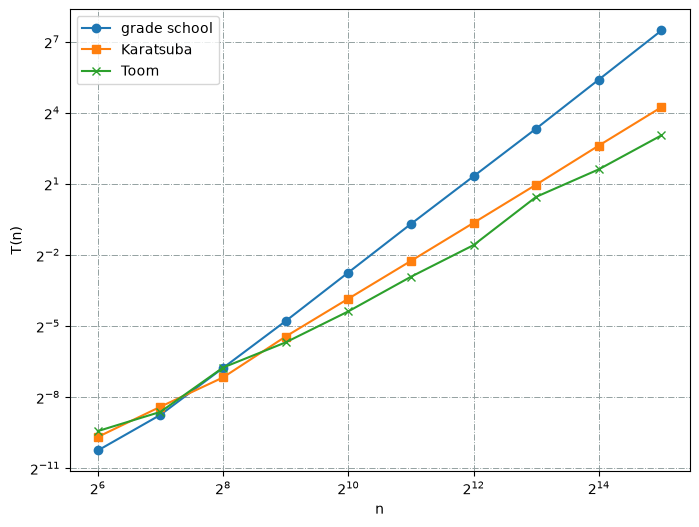

In [7]:
import time
import numpy as np
import random
import string
import sys
import matplotlib.pyplot as plt

sys.set_int_max_str_digits(100000)
np.random.seed(0)


def align(x: str, y: str, n_x: int, n_y: int) -> tuple[str, str, int]:
    # 将字符串数字x和y左补零至等长 返回对齐后的字符串和统一长度
    if n_x < n_y:
        x = x.rjust(n_y, "0")
        n = n_y
    else:
        y = y.rjust(n_x, "0")
        n = n_x
    return x, y, n


def grade_school(x: str, y: str) -> int:
    n_x, n_y = len(x), len(y)
    x, y, n = align(x, y, n_x, n_y)  # 若x和y长度不同 将短的左边补零

    x_list = [int(ch) for ch in x]
    y_list = [int(ch) for ch in y]

    carry = 0  # 初始进位为零
    z: list[str] = []
    for k in range(2 * n):
        # 遍历所有满足i+j=k的二元组(i,j) 注意不要越界
        low = max(0, k - n + 1)
        high = min(k + 1, n)
        for i in range(low, high):
            j = k - i
            carry += x_list[-1 - i] * y_list[-1 - j]
        carry, q = divmod(carry, 10)
        z.append(str(q))

    # z中低位在前、高位在后 翻转得到正常顺序
    result = "".join(reversed(z)).lstrip("0")
    return int(result) if result else 0


def karatsuba(x: str, y: str) -> int:
    n_x, n_y = len(x), len(y)

    if n_x == 1 or n_y == 1:  # 如果其中一个数只有1位 不再递归
        return int(x) * int(y)

    x, y, n = align(x, y, n_x, n_y)  # 若x和y长度不同 将短的左边补零

    m = n // 2
    a, b = x[:n - m], x[n - m:]  # x = a * 10^m + b
    c, d = y[:n - m], y[n - m:]  # y = c * 10^m + d

    a_int, b_int = int(a), int(b)
    c_int, d_int = int(c), int(d)

    # 3个递归子问题
    ac = karatsuba(a, c)
    bd = karatsuba(b, d)
    ad_bc = karatsuba(str(a_int + b_int), str(c_int + d_int)) - ac - bd

    return ac * 10**(2 * m) + ad_bc * 10**m + bd


def preprocess(x: str) -> tuple[int, int, str]:
    # 去除负号前缀 返回 (符号, 有效位数, 纯数字字符串)
    if x[0] == "-":
        return -1, len(x) - 1, x[1:]
    return 1, len(x), x


def toom(x: str, y: str) -> int:
    sign_x, n_x, x = preprocess(x)
    sign_y, n_y, y = preprocess(y)
    sign = sign_x * sign_y

    if n_x <= 2 or n_y <= 2:  # 如果其中一个数小于3位 不再递归
        return sign * int(x) * int(y)

    x, y, n = align(x, y, n_x, n_y)  # 若x和y长度不同 将短的左边补零

    m = n // 3

    a, b, c = x[:n - 2 * m], x[n - 2 * m:n - m], x[n - m:]
    d, e, f = y[:n - 2 * m], y[n - 2 * m:n - m], y[n - m:]

    a_int, b_int, c_int = int(a), int(b), int(c)
    d_int, e_int, f_int = int(d), int(e), int(f)

    # 5个递归子问题
    s4 = toom(a, d)  # s4 = ad
    s3 = toom(str(4 * a_int + 2 * b_int + c_int),
              str(4 * d_int + 2 * e_int + f_int))  # s3 = (4a+2b+c)(4d+2e+f)
    s2 = toom(str(a_int - b_int + c_int),
              str(d_int - e_int + f_int))  # s2 = (a-b+c)(d-e+f)
    s1 = toom(str(a_int + b_int + c_int),
              str(d_int + e_int + f_int))  # s1 = (a+b+c)(d+e+f)
    s0 = toom(c, f)  # s0 = cf

    w4 = s4
    w3 = (-12 * s4 + s3 - s2 - 3 * s1 + 3 * s0) // 6
    w2 = (-2 * s4 + s2 + s1 - 2 * s0) // 2
    w1 = (12 * s4 - s3 - 2 * s2 + 6 * s1 - 3 * s0) // 6
    w0 = s0

    return sign * (w4 * 10**(4 * m) + w3 * 10**(3 * m) + w2 * 10**(2 * m) + w1 * 10**m + w0)


trial = 10
time_cost = np.empty([trial, 4])
for t in range(trial):
    n = 2**(t + 6)  # 2^4, 2^5, ..., 2^13

    # 随机生成长度为n的字符串x和y
    x = ''.join(random.choices(string.digits, k=n))
    y = ''.join(random.choices(string.digits, k=n))

    start = time.perf_counter()
    z0 = int(x) * int(y)
    time_cost[t, 0] = time.perf_counter() - start

    start = time.perf_counter()
    z1 = grade_school(x, y)
    time_cost[t, 1] = time.perf_counter() - start

    start = time.perf_counter()
    z2 = karatsuba(x, y)
    time_cost[t, 2] = time.perf_counter() - start

    start = time.perf_counter()
    z3 = toom(x, y)
    time_cost[t, 3] = time.perf_counter() - start


plt.subplots(figsize=(8, 6))
n = [2**(t + 6) for t in range(trial)]
plt.loglog(n, time_cost[:, 1], base=2, marker='o', label="grade school")
plt.loglog(n, time_cost[:, 2], base=2, marker='s', label="Karatsuba")
plt.loglog(n, time_cost[:, 3], base=2, marker='x', label="Toom")
plt.xlabel("n")
plt.ylabel("T(n)")
plt.grid(color='#93a1a1', linestyle='-.', linewidth=0.7)
plt.legend()
plt.show()